In [31]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split 
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset,DataLoader
import torch.optim as optim

In [5]:
concrete_df = pd.read_excel("Concrete_Data.xls")

In [7]:
concrete_df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [10]:
concrete_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   Cement (component 1)(kg in a m^3 mixture)              1030 non-null   float64
 1   Blast Furnace Slag (component 2)(kg in a m^3 mixture)  1030 non-null   float64
 2   Fly Ash (component 3)(kg in a m^3 mixture)             1030 non-null   float64
 3   Water  (component 4)(kg in a m^3 mixture)              1030 non-null   float64
 4   Superplasticizer (component 5)(kg in a m^3 mixture)    1030 non-null   float64
 5   Coarse Aggregate  (component 6)(kg in a m^3 mixture)   1030 non-null   float64
 6   Fine Aggregate (component 7)(kg in a m^3 mixture)      1030 non-null   float64
 7   Age (day)                                              1030 non-null   int64  
 8   Concrete compressive strength(MPa, megapascals)        1030 

In [11]:
concrete_df.describe()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.165631,73.895485,54.187136,181.566359,6.203112,972.918592,773.578883,45.662136,35.817836
std,104.507142,86.279104,63.996469,21.355567,5.973492,77.753818,80.175427,63.169912,16.705679
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.707115
50%,272.900000,22.000000,0.000000,185.000000,6.350000,968.000000,779.510000,28.000000,34.442774
75%,350.000000,142.950000,118.270000,192.000000,10.160000,1029.400000,824.000000,56.000000,46.136287
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


In [12]:
concrete_df.isnull().sum()

Cement (component 1)(kg in a m^3 mixture)                0
Blast Furnace Slag (component 2)(kg in a m^3 mixture)    0
Fly Ash (component 3)(kg in a m^3 mixture)               0
Water  (component 4)(kg in a m^3 mixture)                0
Superplasticizer (component 5)(kg in a m^3 mixture)      0
Coarse Aggregate  (component 6)(kg in a m^3 mixture)     0
Fine Aggregate (component 7)(kg in a m^3 mixture)        0
Age (day)                                                0
Concrete compressive strength(MPa, megapascals)          0
dtype: int64

In [13]:
concrete_df.columns

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='str')

In [18]:
X = concrete_df.drop("Concrete compressive strength(MPa, megapascals) ",axis=1)
y = concrete_df["Concrete compressive strength(MPa, megapascals) "]

In [21]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
X_train_tensor = torch.tensor(X_train_scaled,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled,dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)
y_test_tensor = torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [27]:
train_dataset = TensorDataset(X_train_tensor,y_train_tensor)
test_dataset = TensorDataset(X_test_tensor,y_test_tensor)

In [28]:
train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32)

In [30]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model = nn.Sequential(

            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),

            nn.Linear(6,6),
            nn.ReLU(),

            nn.Linear(6,1),
        )

    def forward(self,x):
        return self.model(x)

In [33]:
model = ANN()

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [37]:
train_losses = []
val_losses = []
epochs = 100

best_val_loss = float("inf") 

for epoch in range(epochs):
    model.train()

    running_loss = 0.0
    for xb,yb in train_loader:
    
        optimizer.zero_grad()
    
        outputs = model(xb)
        loss = criterion(outputs,yb)
        loss.backward()
        optimizer.step()
    
        running_loss += loss.item()
        
    epoch_train_loss = running_loss/len(train_loader)
    train_losses.append(epoch_train_loss)

    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb,yb in test_loader:
            outputs = model(xb)
            loss = criterion(outputs,yb)
            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss/len(test_loader)
    val_losses.append(epoch_val_loss)

    print(
    f"Epoch {epoch+1}/{epochs} ==> "
    f"Training Loss = {epoch_train_loss:.4f} | "
    f"Validation Loss = {epoch_val_loss:.4f}"
)       

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(),"best_model.pt") #pt or pth file

Epoch 1/100 ==> Training Loss = 125.7161 | Validation Loss = 112.5712
Epoch 2/100 ==> Training Loss = 124.5009 | Validation Loss = 112.2139
Epoch 3/100 ==> Training Loss = 124.9503 | Validation Loss = 111.7502
Epoch 4/100 ==> Training Loss = 124.2891 | Validation Loss = 111.4607
Epoch 5/100 ==> Training Loss = 123.7638 | Validation Loss = 111.0585
Epoch 6/100 ==> Training Loss = 123.7088 | Validation Loss = 110.5551
Epoch 7/100 ==> Training Loss = 123.4231 | Validation Loss = 110.6824
Epoch 8/100 ==> Training Loss = 123.4319 | Validation Loss = 109.9733
Epoch 9/100 ==> Training Loss = 123.3242 | Validation Loss = 110.0371
Epoch 10/100 ==> Training Loss = 121.9427 | Validation Loss = 109.7216
Epoch 11/100 ==> Training Loss = 122.2213 | Validation Loss = 109.5024
Epoch 12/100 ==> Training Loss = 121.2677 | Validation Loss = 109.4480
Epoch 13/100 ==> Training Loss = 120.8121 | Validation Loss = 109.2242
Epoch 14/100 ==> Training Loss = 121.3789 | Validation Loss = 109.0944
Epoch 15/100 ==

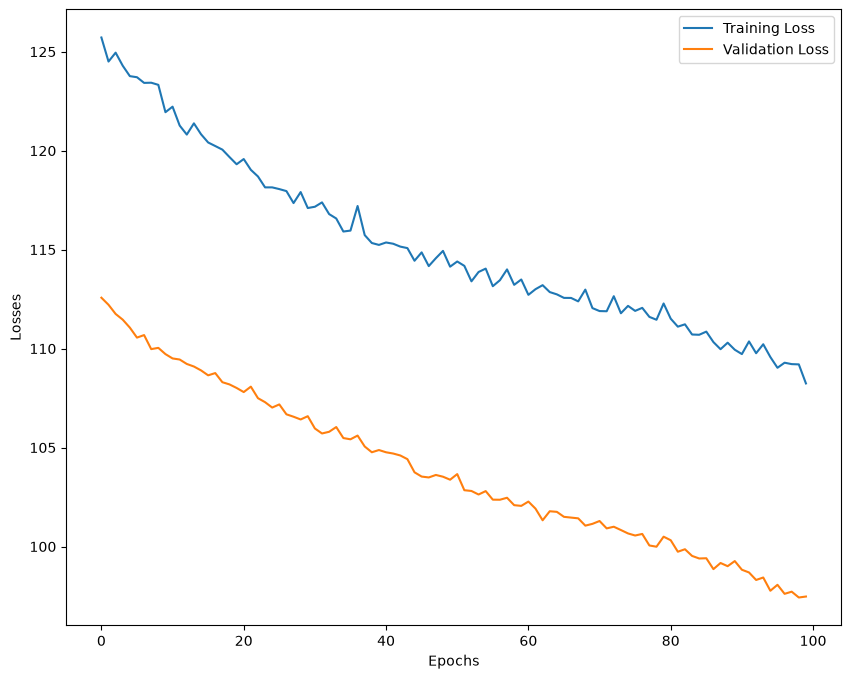

In [38]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss" : train_losses,
    "Validation Loss" : val_losses
})

plt.figure(figsize=(10,8))
plt.plot(loss_df["Training Loss"],label="Training Loss")
plt.plot(loss_df["Validation Loss"],label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [39]:
#Evaluate our Model

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = criterion(train_preds,y_train_tensor)
    test_mse_loss = criterion(test_preds,y_test_tensor)
    
print("Training MSE : ",train_mse_loss.item())
print("Testing MSE : ",test_mse_loss.item())

Training MSE :  108.36627960205078
Testing MSE :  94.59143829345703


In [40]:
from sklearn.metrics import r2_score

print("R2 Score : ",r2_score(y_test,test_preds)*100)

R2 Score :  63.29127956833675


In [41]:
predicted_df = pd.DataFrame(test_preds.numpy(),columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values,columns=["Actual Values"])

pd.concat([predicted_df,actual_df],axis=1)

,Predicted Values,Actual Values
0,57.647884,52.908320
1,51.163563,55.895819
2,63.738518,74.497882
3,50.655994,35.301171
4,18.461445,10.535193
...,...,...
201,55.962845,56.144031
202,16.921759,18.746163
203,49.783180,37.997022
204,55.805725,74.364911
